# 타이타닉 생존 데이터 분석
데이터 로드 → 클렌징 → 다각도 분석 → 성별 생존율 막대그래프

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'  # 한글 폰트 (Windows)
plt.rcParams['axes.unicode_minus'] = False

url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. 데이터 탐색

In [2]:
print(df.shape)
df.info()
print(df.isnull().sum())
print('중복 행:', df.duplicated().sum())
df.describe()

(891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
중복 행: 0


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 2. 데이터 클렌징

In [3]:
clean = df.copy()

# 중복 제거
clean = clean.drop_duplicates()

# 호칭(Title) 추출 후 호칭별 중앙값으로 나이 결측치 보정
clean['Title'] = clean['Name'].str.extract(r',\s*([^\.]+)\.', expand=False).str.strip()
clean['Age'] = clean['Age'].fillna(clean.groupby('Title')['Age'].transform('median'))
clean['Age'] = clean['Age'].fillna(clean['Age'].median())

# 탑승 항구 결측치는 최빈값, 요금 결측치는 중앙값
clean['Embarked'] = clean['Embarked'].fillna(clean['Embarked'].mode()[0])
clean['Fare'] = clean['Fare'].fillna(clean['Fare'].median())

# 객실 정보: 결측이 매우 많으므로 보유 여부 파생변수로 대체
clean['HasCabin'] = clean['Cabin'].notnull().astype(int)
clean = clean.drop(columns=['Cabin', 'Ticket'])

# 문자열 공백 정리 및 타입 변환
clean['Sex'] = clean['Sex'].str.strip().str.lower()
clean['Survived'] = clean['Survived'].astype(int)
clean['Pclass'] = clean['Pclass'].astype('category')

# 파생변수
clean['FamilySize'] = clean['SibSp'] + clean['Parch'] + 1
clean['IsAlone'] = (clean['FamilySize'] == 1).astype(int)
clean['AgeGroup'] = pd.cut(clean['Age'], bins=[0, 12, 19, 35, 60, 120],
                           labels=['어린이', '청소년', '청년', '중장년', '노년'])

print(clean.isnull().sum())
clean.head()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
Title          0
HasCabin       0
FamilySize     0
IsAlone        0
AgeGroup       0
dtype: int64


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Title,HasCabin,FamilySize,IsAlone,AgeGroup
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S,Mr,0,2,0,청년
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C,Mrs,1,2,0,중장년
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S,Miss,0,1,1,청년
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S,Mrs,1,2,0,청년
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S,Mr,0,1,1,청년


## 3. 다각도 분석

In [4]:
print('전체 생존율: {:.1%}'.format(clean['Survived'].mean()))
for col in ['Sex', 'Pclass', 'Embarked', 'AgeGroup', 'IsAlone']:
    print(f'\n[{col}별 생존율]')
    print(clean.groupby(col, observed=True)['Survived'].agg(['mean', 'sum', 'count']).round(3))

print('\n[성별 x 객실등급 생존율]')
print(clean.pivot_table(values='Survived', index='Sex', columns='Pclass', observed=True).round(3))

print('\n[수치형 상관관계]')
clean[['Survived', 'Age', 'Fare', 'SibSp', 'Parch', 'FamilySize', 'HasCabin']].corr().round(2)

전체 생존율: 38.4%

[Sex별 생존율]
         mean  sum  count
Sex                      
female  0.742  233    314
male    0.189  109    577

[Pclass별 생존율]
         mean  sum  count
Pclass                   
1       0.630  136    216
2       0.473   87    184
3       0.242  119    491

[Embarked별 생존율]
           mean  sum  count
Embarked                   
C         0.554   93    168
Q         0.390   30     77
S         0.339  219    646

[AgeGroup별 생존율]
           mean  sum  count
AgeGroup                   
어린이       0.575   42     73
청소년       0.411   39     95
청년        0.352  178    505
중장년       0.398   78    196
노년        0.227    5     22

[IsAlone별 생존율]
          mean  sum  count
IsAlone                   
0        0.506  179    354
1        0.304  163    537

[성별 x 객실등급 생존율]
Pclass      1      2      3
Sex                        
female  0.968  0.921  0.500
male    0.369  0.157  0.135

[수치형 상관관계]


,Survived,Age,Fare,SibSp,Parch,FamilySize,HasCabin
Survived,1.00,-0.08,0.26,-0.04,0.08,0.02,0.32
Age,-0.08,1.00,0.10,-0.27,-0.19,-0.28,0.24
Fare,0.26,0.10,1.00,0.16,0.22,0.22,0.48
SibSp,-0.04,-0.27,0.16,1.00,0.41,0.89,-0.04
Parch,0.08,-0.19,0.22,0.41,1.00,0.78,0.04
FamilySize,0.02,-0.28,0.22,0.89,0.78,1.00,-0.01
HasCabin,0.32,0.24,0.48,-0.04,0.04,-0.01,1.00


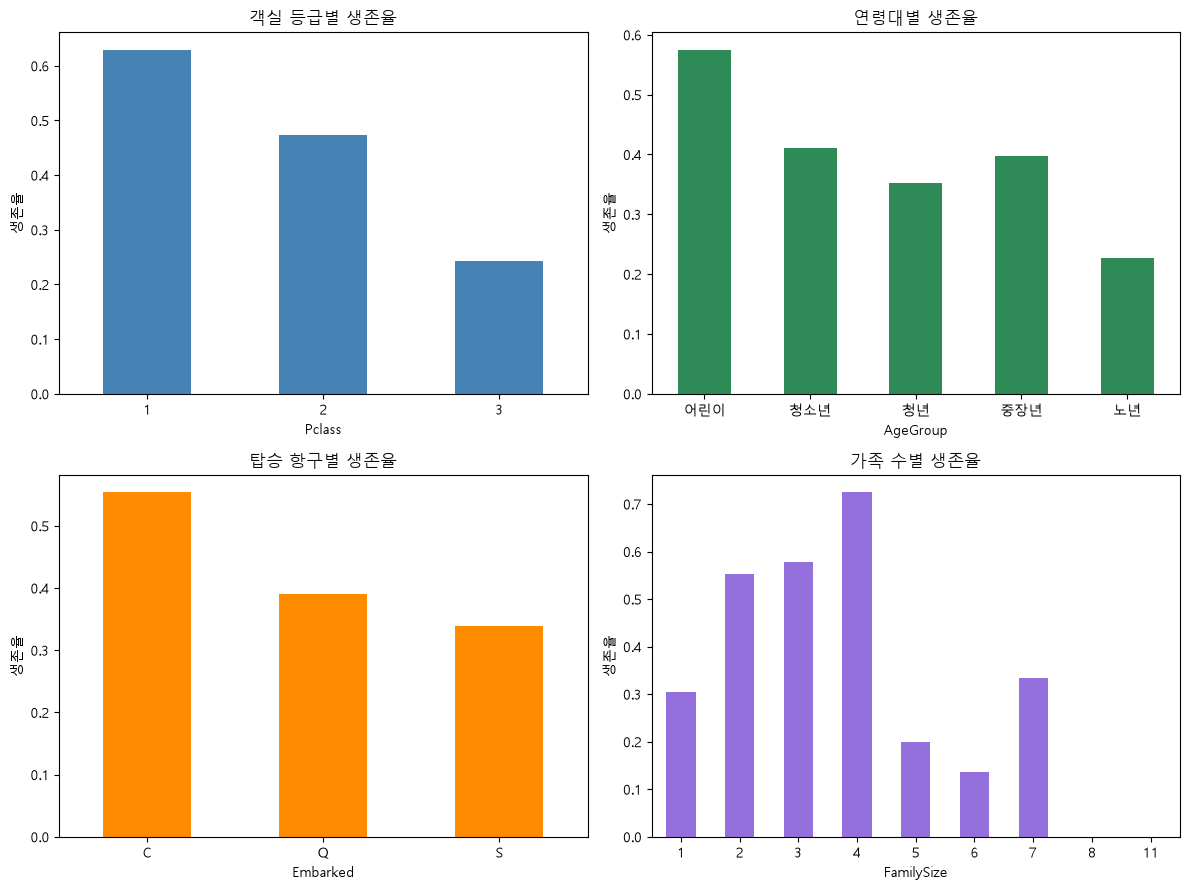

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

clean.groupby('Pclass', observed=True)['Survived'].mean().plot(kind='bar', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('객실 등급별 생존율')

clean.groupby('AgeGroup', observed=True)['Survived'].mean().plot(kind='bar', ax=axes[0, 1], color='seagreen')
axes[0, 1].set_title('연령대별 생존율')

clean.groupby('Embarked')['Survived'].mean().plot(kind='bar', ax=axes[1, 0], color='darkorange')
axes[1, 0].set_title('탑승 항구별 생존율')

clean.groupby('FamilySize')['Survived'].mean().plot(kind='bar', ax=axes[1, 1], color='mediumpurple')
axes[1, 1].set_title('가족 수별 생존율')

for ax in axes.flat:
    ax.set_ylabel('생존율')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 4. 남성과 여성의 생존율 (막대그래프)

Sex
여성    74.2
남성    18.9
Name: Survived, dtype: float64


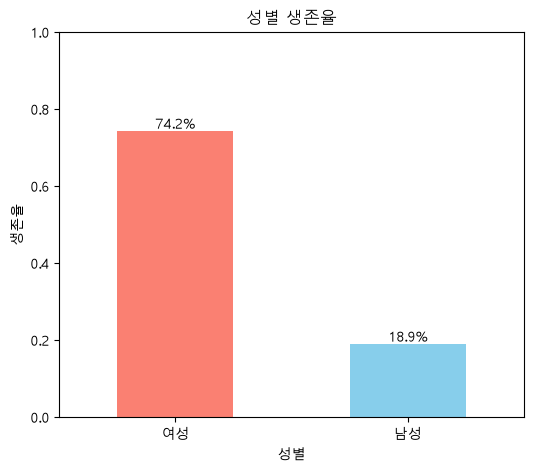

In [6]:
rate = clean.groupby('Sex')['Survived'].mean().rename({'female': '여성', 'male': '남성'})
print((rate * 100).round(1))

ax = rate.plot(kind='bar', color=['salmon', 'skyblue'], figsize=(6, 5))
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1%}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
ax.set_title('성별 생존율')
ax.set_xlabel('성별')
ax.set_ylabel('생존율')
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.show()